<a href="https://colab.research.google.com/github/Rageel-28/PCVK_Ganjil_2026/blob/main/Week5_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import sys, platform, hashlib, datetime, zoneinfo

NAMA = 'Rakagali Resda Krisandi Putra'
NIM  = '244107020136'

N     = int(NIM[-3:])
PARAM = {
    'bins' : 2 ** ((N % 4) + 3),
    'clip' : round(1.0 + (N % 5) * 0.5, 1),
    'tile' : (N % 4) + 2,
    'L'    : 2 ** ((N % 3) + 1),
}
waktu = datetime.datetime.now(zoneinfo.ZoneInfo('Asia/Jakarta'))

print('NAMA   :', NAMA)
print('NIM    :', NIM, '| N =', N)
for k, v in PARAM.items():
    print('%-6s :' % k, v)
print('WAKTU  :', waktu.strftime('%Y-%m-%d %H:%M:%S %Z'))
print('SISTEM :', sys.version.split()[0], platform.platform())
kunci = NIM + '|' + waktu.strftime('%Y-%m-%d')
print('TOKEN  :', hashlib.sha256(kunci.encode()).hexdigest()[:16])


NAMA   : Rakagali Resda Krisandi Putra
NIM    : 244107020136 | N = 136
bins   : 8
clip   : 1.5
tile   : 2
L      : 4
WAKTU  : 2026-09-30 18:56:50 WIB
SISTEM : 3.13.15 Linux-6.6.122+-x86_64-with-glibc2.39
TOKEN  : 9ccfb3065e9f9f6b


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import cv2 as cv
from google.colab.patches import cv2_imshow
from skimage import io
import matplotlib.pyplot as plt
import numpy as np
import math
import os
import glob
import time


In [10]:
CONTOH = '/content/drive/MyDrive/Images'          # citra contoh bersama
BASE   = '/content/drive/MyDrive/Images/' + NIM   # citra KTM milik Anda

# pemeriksaan: semua harus True sebelum lanjut
for f in [CONTOH + '/lena.jpg', CONTOH + '/lena_lc.jpg',
          BASE + '/ktm1a.jpeg', BASE + '/ktm1b.jpeg',
          BASE + '/ktm1c.jpeg', BASE + '/ktm1d.jpeg']:
    print(os.path.exists(f), f)


True /content/drive/MyDrive/Images/lena.jpg
True /content/drive/MyDrive/Images/lena_lc.jpg
True /content/drive/MyDrive/Images/244107020136/ktm1a.jpeg
True /content/drive/MyDrive/Images/244107020136/ktm1b.jpeg
True /content/drive/MyDrive/Images/244107020136/ktm1c.jpeg
True /content/drive/MyDrive/Images/244107020136/ktm1d.jpeg


In [11]:
def histogram_manual(img, L=256):
    h = np.zeros(L, dtype=np.int64)       # 1. siapkan penghitung, isi 0
    for y in range(img.shape[0]):         # 2. telusuri setiap baris
        for x in range(img.shape[1]):     #    dan setiap kolom
            h[img[y, x]] += 1             # 3. tambah 1 sesuai nilai piksel
    return h

def histogram_rgb(path, judul):
    bgr = cv.imread(path)
    assert bgr is not None, 'Berkas tidak terbaca: ' + path
    rgb = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)
    tinggi, lebar, _ = rgb.shape
    print(judul, '->', lebar, 'x', tinggi, 'piksel')
    hasil = [histogram_manual(rgb[:, :, k]) for k in range(3)]
    for nama, h in zip(['R', 'G', 'B'], hasil):
        assert h.sum() == tinggi * lebar          # pemeriksaan wajib
        print(nama, 'jumlah =', h.sum(), '| puncak di intensitas', h.argmax(),
              '| tinggi puncak', h.max())
    names = np.arange(256)
    fig, axs = plt.subplots(1, 3, figsize=(20, 5), sharex=True, sharey=True)
    fig.suptitle(NIM + ' - Histogram RGB ' + judul)
    fig.text(0.09, 0.5, 'Jumlah Kemunculan', va='center', rotation='vertical')
    fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
    for ax, h, w in zip(axs, hasil, ['red', 'green', 'blue']):
        ax.bar(names, h, color=w)
    plt.show()
    return hasil


lena.jpg (tahap 1) -> 512 x 512 piksel
R jumlah = 262144 | puncak di intensitas 218 | tinggi puncak 2793
G jumlah = 262144 | puncak di intensitas 103 | tinggi puncak 1948
B jumlah = 262144 | puncak di intensitas 127 | tinggi puncak 2088


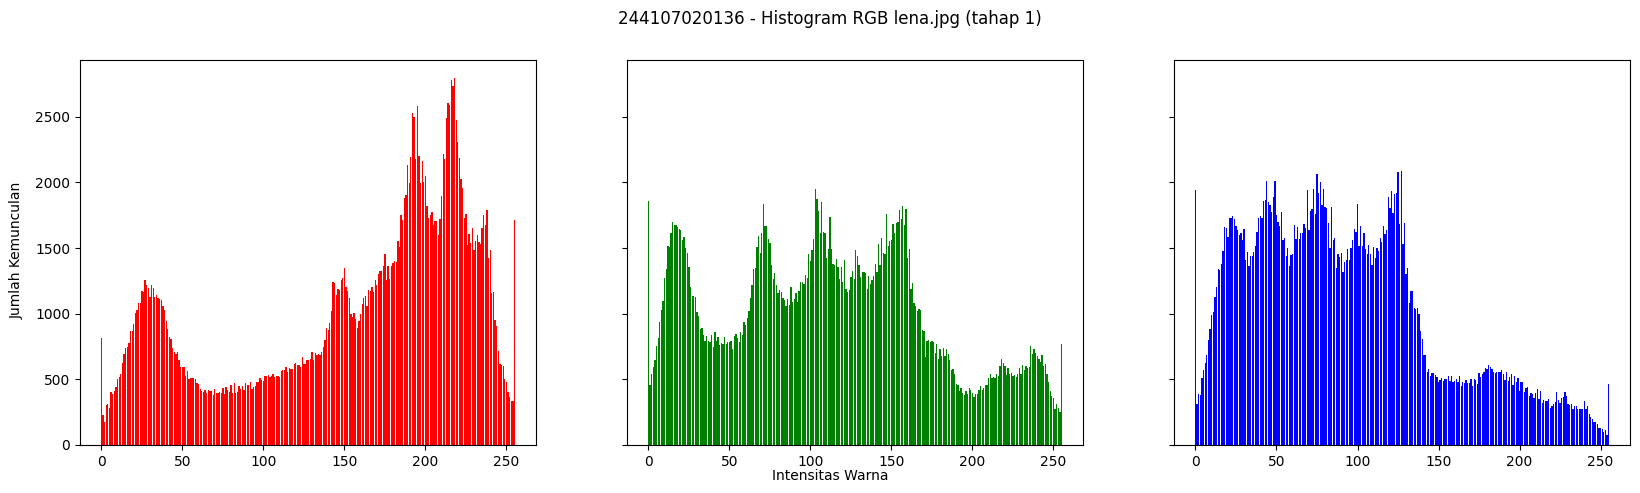

In [12]:
hist_lena = histogram_rgb(CONTOH + '/lena.jpg', 'lena.jpg (tahap 1)')

ktm1b.jpeg (tahap 2) -> 1600 x 885 piksel
R jumlah = 1416000 | puncak di intensitas 229 | tinggi puncak 31204
G jumlah = 1416000 | puncak di intensitas 193 | tinggi puncak 26760
B jumlah = 1416000 | puncak di intensitas 170 | tinggi puncak 41417


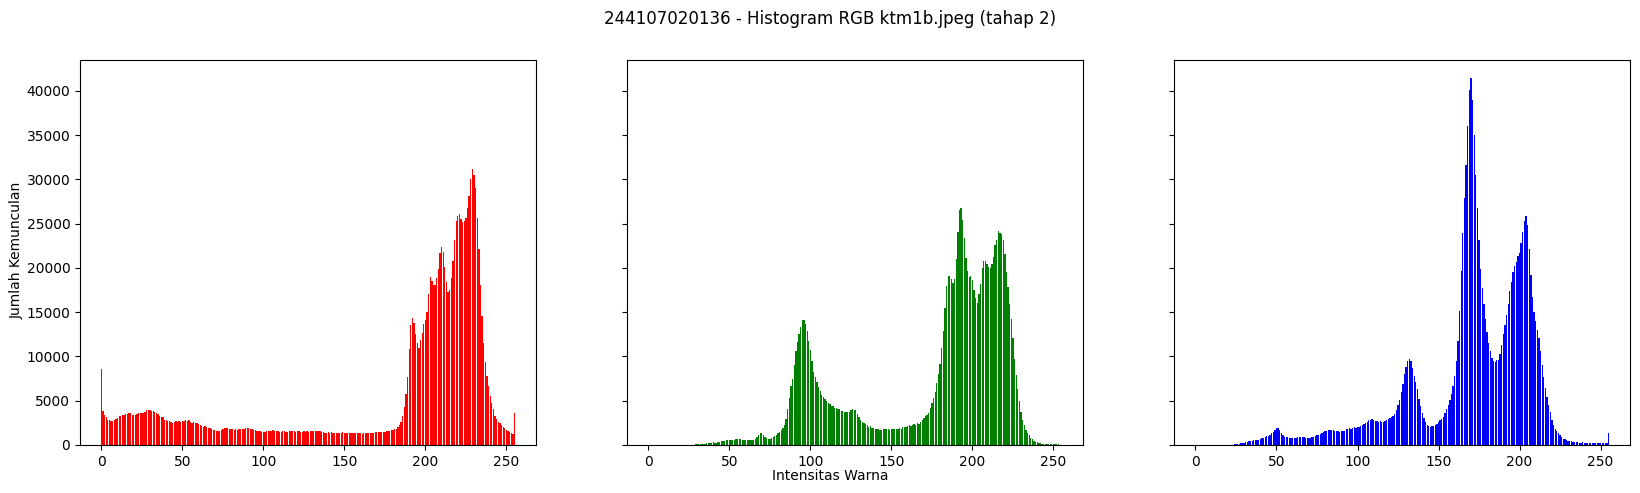

In [14]:
hist_ktm = histogram_rgb(BASE + '/ktm1b.jpeg', 'ktm1b.jpeg (tahap 2)')

ukuran citra   : 1600 x 885 = 1416000 piksel
jumlah h       : 1416000
jumlah p       : 0.9999999999999999
CDF[255]       : 0.9999999999999999
rerata intensitas: 174.97


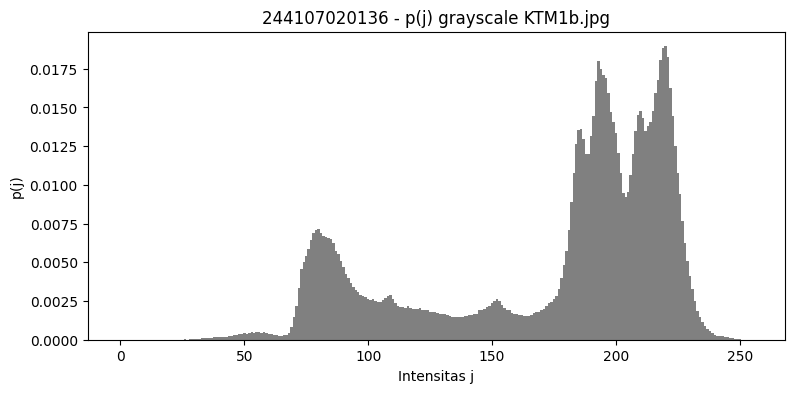

In [16]:
gray = cv.imread(BASE + '/ktm1b.jpeg', cv.IMREAD_GRAYSCALE)
h   = histogram_manual(gray)
p   = h / gray.size                 # 4. normalisasi, jumlahnya = 1
cdf = np.cumsum(p)                  # 5. distribusi kumulatif
assert h.sum() == gray.size         # pemeriksaan wajib

print('ukuran citra   :', gray.shape[1], 'x', gray.shape[0], '=', gray.size, 'piksel')
print('jumlah h       :', h.sum())
print('jumlah p       :', p.sum())
print('CDF[255]       :', cdf[-1])
print('rerata intensitas: %.2f' % gray.mean())

plt.figure(figsize=(9, 4))
plt.bar(np.arange(256), p, width=1.0, color='gray')
plt.title(NIM + ' - p(j) grayscale KTM1b.jpg')
plt.xlabel('Intensitas j'); plt.ylabel('p(j)')
plt.show()


**SOAL 1**

In [18]:
def hist_np(g):
    return np.histogram(g.ravel(), bins=256, range=(0, 256))[0].astype(np.int64)

def hist_cv(g):
    return cv.calcHist([g], [0], None, [256], [0, 256]).ravel().astype(np.int64)

def bandingkan(path, judul):
    g = cv.imread(path, cv.IMREAD_GRAYSCALE)
    t0 = time.perf_counter(); h1 = histogram_manual(g)
    t1 = time.perf_counter(); h2 = hist_np(g)
    t2 = time.perf_counter(); h3 = hist_cv(g)
    t3 = time.perf_counter()
    print('==', judul, '|', g.shape[1], 'x', g.shape[0], '==')
    print('max|manual - numpy|    =', np.abs(h1 - h2).max())
    print('max|manual - calcHist| =', np.abs(h1 - h3).max())
    print('max|numpy  - calcHist| =', np.abs(h2 - h3).max())
    print('waktu: manual %.4f s | numpy %.5f s | calcHist %.5f s'
          % (t1 - t0, t2 - t1, t3 - t2))
    assert np.array_equal(h1, h2) and np.array_equal(h1, h3)

bandingkan(CONTOH + '/lena.jpg', 'lena.jpg (tahap 1)')
bandingkan(BASE + '/ktm1b.jpeg', 'ktm1b.jpeg (tahap 2)')


== lena.jpg (tahap 1) | 512 x 512 ==
max|manual - numpy|    = 0
max|manual - calcHist| = 0
max|numpy  - calcHist| = 0
waktu: manual 0.1289 s | numpy 0.00388 s | calcHist 0.00033 s
== ktm1b.jpeg (tahap 2) | 1600 x 885 ==
max|manual - numpy|    = 0
max|manual - calcHist| = 0
max|numpy  - calcHist| = 0
waktu: manual 0.7261 s | numpy 0.01789 s | calcHist 0.00103 s


**SOAL 2**

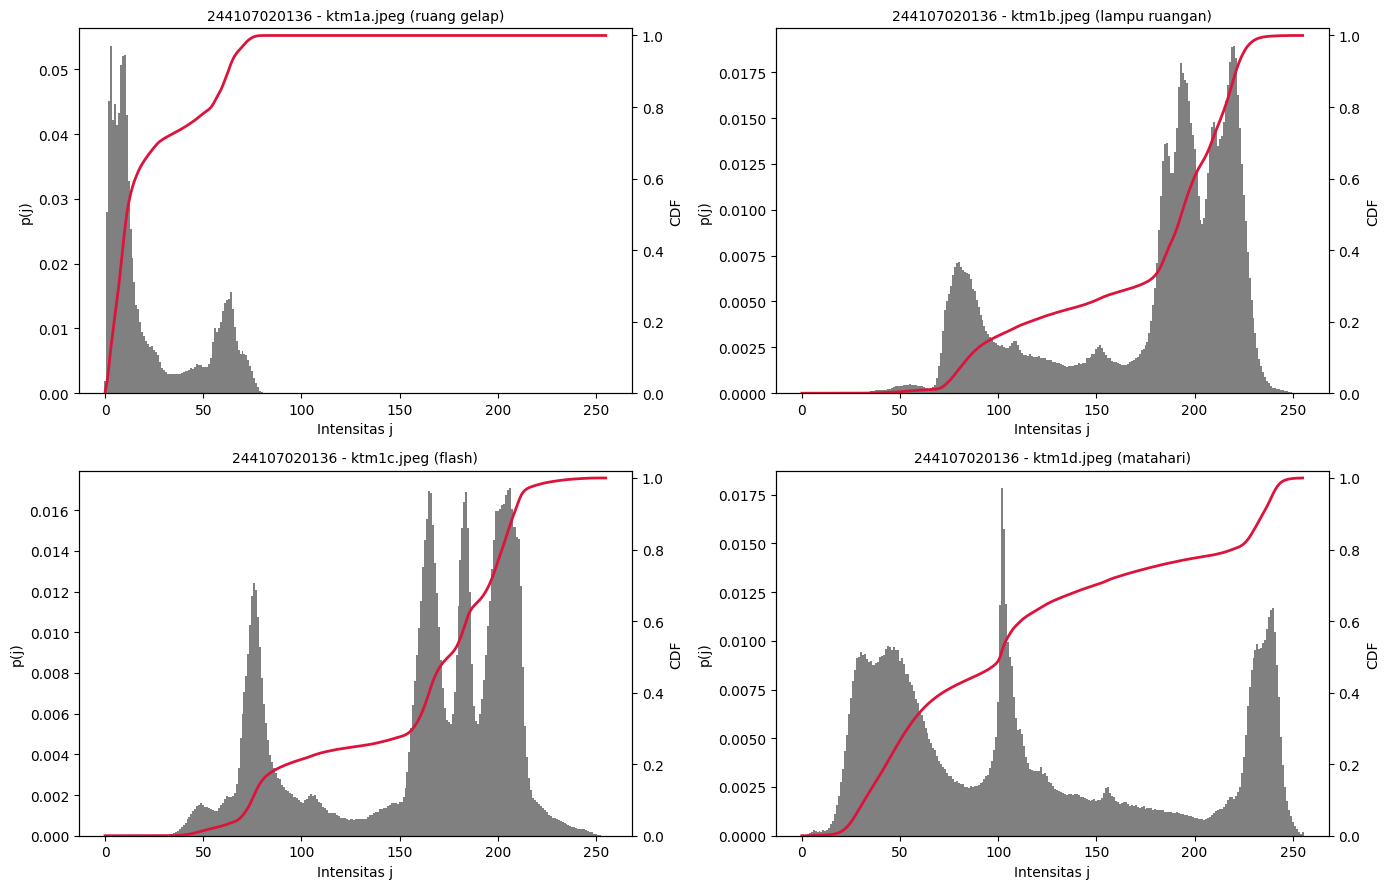

Berkas       Rerata   Median      P90       %<64     %>=192
ktm1a.jpeg     23.5       12       63       90.4        0.0
ktm1b.jpeg    175.0      194      222        1.0       53.9
ktm1c.jpeg    159.7      175      209        3.4       33.9
ktm1d.jpeg    114.9      101      235       36.2       23.3


In [19]:
files = ['ktm1a.jpeg', 'ktm1b.jpeg', 'ktm1c.jpeg', 'ktm1d.jpeg']
ket   = ['ruang gelap', 'lampu ruangan', 'flash', 'matahari']
x = np.arange(256)
stat = []

fig, axs = plt.subplots(2, 2, figsize=(14, 9))
for ax, f, k in zip(axs.ravel(), files, ket):
    g = cv.imread(BASE + '/' + f, cv.IMREAD_GRAYSCALE)
    p = hist_np(g) / g.size                 # histogram ternormalisasi p(j)
    cdf = np.cumsum(p)                      # kurva CDF
    ax.bar(x, p, width=1.0, color='gray')
    ax.set_xlabel('Intensitas j'); ax.set_ylabel('p(j)')
    ax2 = ax.twinx()
    ax2.plot(x, cdf, color='crimson', lw=2)
    ax2.set_ylim(0, 1.02); ax2.set_ylabel('CDF')
    ax.set_title(NIM + ' - ' + f + ' (' + k + ')', fontsize=10)
    stat.append((f, g.mean(), np.searchsorted(cdf, 0.5),
                 np.searchsorted(cdf, 0.9), 100 * p[:64].sum(), 100 * p[192:].sum()))
plt.tight_layout()
plt.show()

print('%-10s %8s %8s %8s %10s %10s' % ('Berkas', 'Rerata', 'Median', 'P90', '%<64', '%>=192'))
for s in stat:
    print('%-10s %8.1f %8d %8d %10.1f %10.1f' % s)


**SOAL 3**

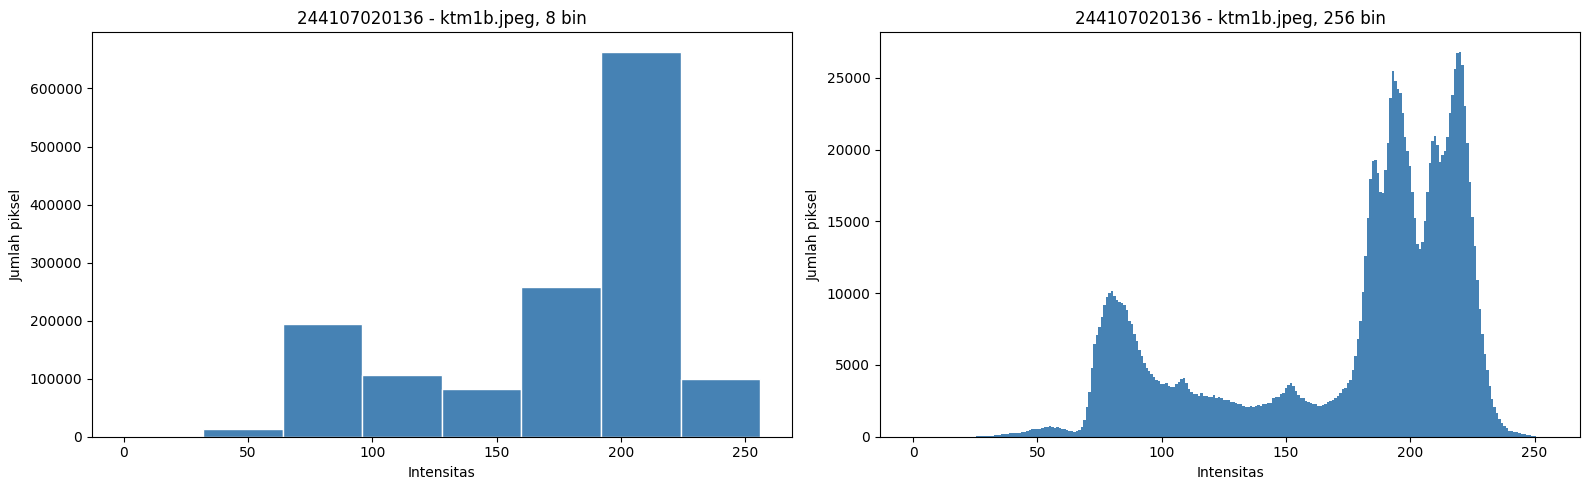

lebar tiap bin (level yang digabung) : 32
bin terisi   : 8 dari 8
level terisi : 242 dari 256
puncak 8 bin : bin ke-6 = intensitas 192-223, jumlah 663544
puncak 256 bin: intensitas 220, jumlah 26824
total piksel sama? True


In [21]:
g = cv.imread(BASE + '/ktm1b.jpeg', cv.IMREAD_GRAYSCALE)
B = PARAM['bins']
h_b, tepi = np.histogram(g, bins=B, range=(0, 256))
h_256 = hist_np(g)

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
axs[0].bar(tepi[:-1], h_b, width=256 / B, align='edge',
           color='steelblue', edgecolor='white')
axs[0].set_title(NIM + ' - ktm1b.jpeg, ' + str(B) + ' bin')
axs[1].bar(np.arange(256), h_256, width=1.0, color='steelblue')
axs[1].set_title(NIM + ' - ktm1b.jpeg, 256 bin')
for a in axs:
    a.set_xlabel('Intensitas'); a.set_ylabel('Jumlah piksel')
plt.tight_layout()
plt.show()

ib = int(h_b.argmax())
print('lebar tiap bin (level yang digabung) :', 256 // B)
print('bin terisi   :', np.count_nonzero(h_b), 'dari', B)
print('level terisi :', np.count_nonzero(h_256), 'dari 256')
print('puncak %d bin : bin ke-%d = intensitas %d-%d, jumlah %d'
      % (B, ib, tepi[ib], tepi[ib + 1] - 1, h_b.max()))
print('puncak 256 bin: intensitas %d, jumlah %d' % (h_256.argmax(), h_256.max()))
print('total piksel sama?', h_b.sum() == h_256.sum() == g.size)


**E2**

In [22]:
def he_manual(kanal, k=8):
    h  = hist_np(kanal)                               # 1. frekuensi tiap nilai
    C  = np.cumsum(h)                                 # 2. jumlah kumulatif
    p  = C / kanal.size                               # 3. dibagi jumlah piksel (w*h)
    Ko = np.round(p * (2 ** k - 1)).astype(np.uint8)  # 4. rumus Ko
    return Ko[kanal]                                  # 5. set piksel nilai baru

def he_tampil(path, judul):
    bgr = cv.imread(path)
    assert bgr is not None, 'Berkas tidak terbaca: ' + path
    hasil = cv.merge([he_manual(c) for c in cv.split(bgr)])

    fig, axs = plt.subplots(1, 2, figsize=(12, 6))
    axs[0].imshow(cv.cvtColor(bgr, cv.COLOR_BGR2RGB))
    axs[0].set_title(NIM + ' - ' + judul + ' (asli)')
    axs[1].imshow(cv.cvtColor(hasil, cv.COLOR_BGR2RGB))
    axs[1].set_title(NIM + ' - ' + judul + ' (HE manual)')
    for a in axs:
        a.axis('off')
    plt.show()

    fig, axs = plt.subplots(2, 3, figsize=(20, 8), sharex=True)
    fig.suptitle(NIM + ' - Histogram RGB ' + judul)
    fig.text(0.09, 0.5, 'Jumlah Kemunculan (atas: asli, bawah: HE manual)',
             va='center', rotation='vertical')
    fig.text(0.5, 0.04, 'Intensitas Warna', ha='center')
    for j, (idx, w) in enumerate([(2, 'red'), (1, 'green'), (0, 'blue')]):
        axs[0, j].bar(np.arange(256), hist_np(bgr[:, :, idx]), color=w)
        axs[1, j].bar(np.arange(256), hist_np(hasil[:, :, idx]), color=w)
    plt.show()

    for nama, idx in [('R', 2), ('G', 1), ('B', 0)]:
        a, b = bgr[:, :, idx], hasil[:, :, idx]
        print(nama, '| rentang asli', a.min(), '-', a.max(),
              '| hasil', b.min(), '-', b.max(),
              '| std %.1f -> %.1f' % (a.std(), b.std()))
    return bgr, hasil


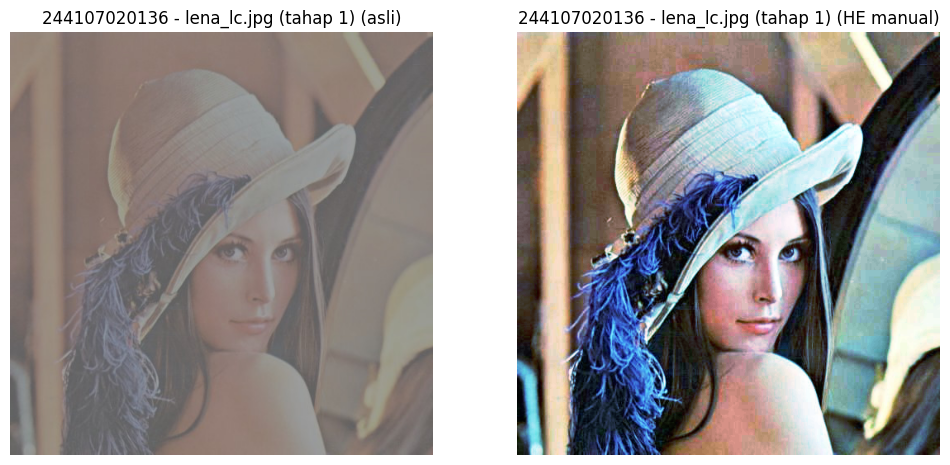

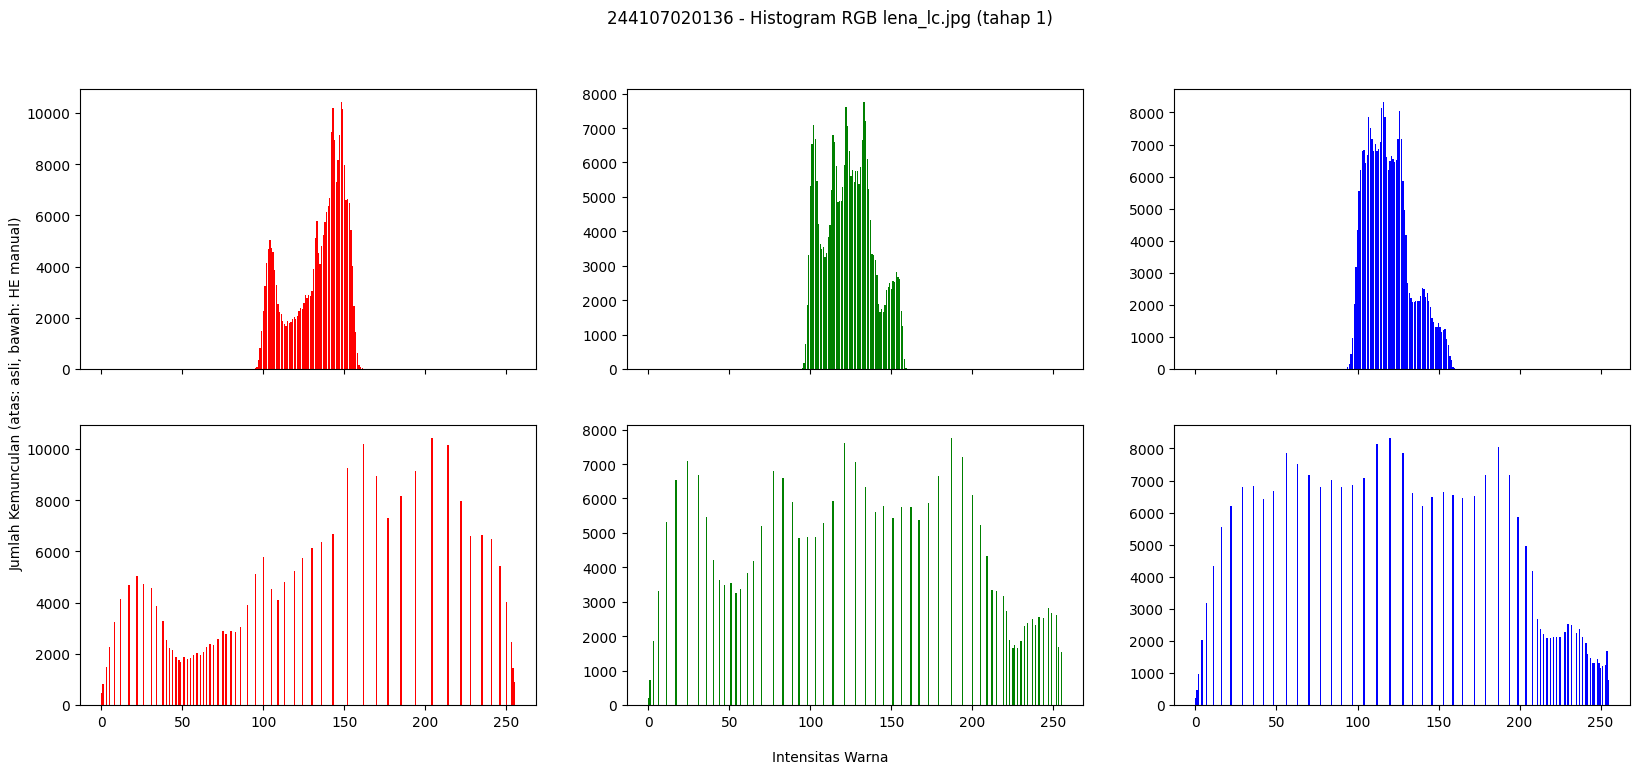

R | rentang asli 92 - 164 | hasil 0 - 255 | std 16.7 -> 74.3
G | rentang asli 94 - 160 | hasil 0 - 255 | std 15.2 -> 73.4
B | rentang asli 89 - 161 | hasil 0 - 255 | std 13.7 -> 73.1


In [23]:
lena_lc, lena_lc_he = he_tampil(CONTOH + '/lena_lc.jpg', 'lena_lc.jpg (tahap 1)')

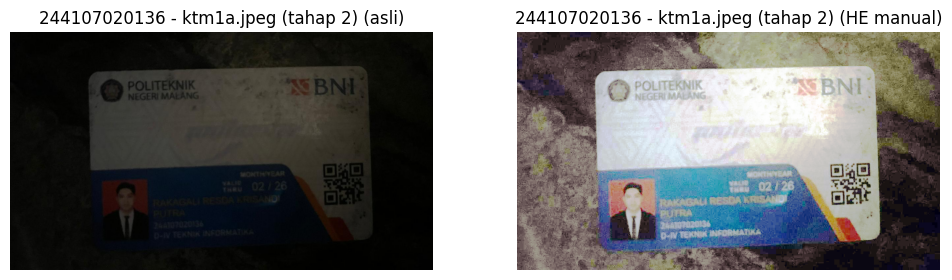

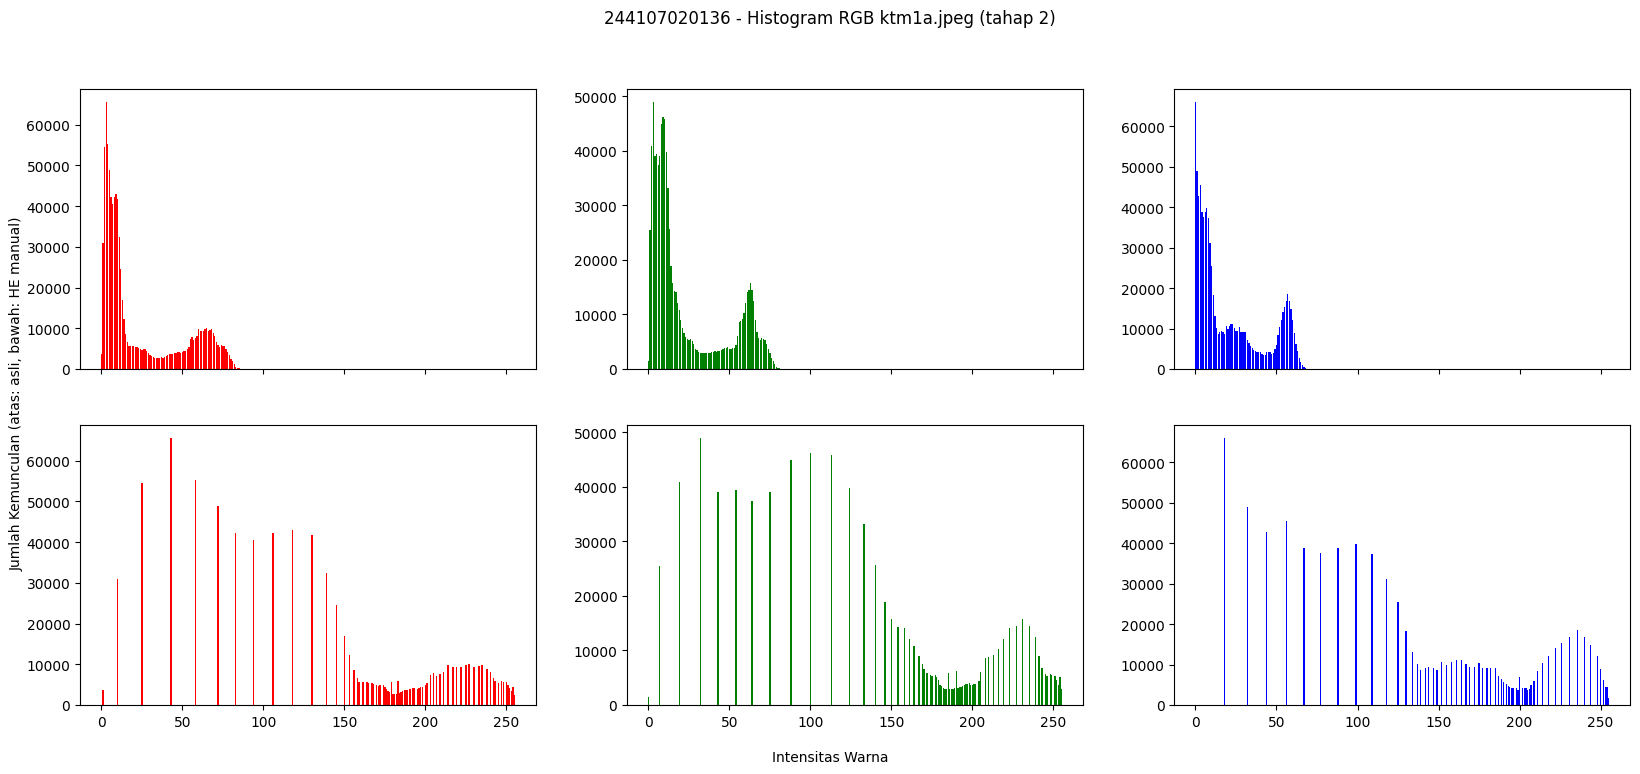

R | rentang asli 0 - 93 | hasil 1 - 255 | std 25.1 -> 70.9
G | rentang asli 0 - 85 | hasil 0 - 255 | std 23.1 -> 71.8
B | rentang asli 0 - 73 | hasil 18 - 255 | std 20.6 -> 71.3


In [25]:
ktm1a, ktm1a_he = he_tampil(BASE + '/ktm1a.jpeg', 'ktm1a.jpeg (tahap 2)')

In [26]:
def he_opencv(bgr):
    b, g, r = cv.split(bgr)
    return cv.merge([cv.equalizeHist(b), cv.equalizeHist(g), cv.equalizeHist(r)])

def he_manual_cdfmin(kanal):      # varian: level terendah yang terisi -> 0
    C = np.cumsum(hist_np(kanal))
    cmin = C[C > 0][0]
    lut = np.round((C - cmin) / (kanal.size - cmin) * 255)
    return lut.clip(0, 255).astype(np.uint8)[kanal]

def selisih(nama, asli):
    cvh  = he_opencv(asli)
    man  = cv.merge([he_manual(c) for c in cv.split(asli)])
    man2 = cv.merge([he_manual_cdfmin(c) for c in cv.split(asli)])
    d1 = np.abs(man.astype(int) - cvh.astype(int))
    d2 = np.abs(man2.astype(int) - cvh.astype(int))
    print('==', nama, '==')
    print('rumus modul vs equalizeHist: maks %d | rerata %.3f | beda %.1f%%'
          % (d1.max(), d1.mean(), 100 * (d1 > 0).mean()))
    print('varian cdf_min vs equalizeHist: maks %d | rerata %.3f | beda %.1f%%'
          % (d2.max(), d2.mean(), 100 * (d2 > 0).mean()))
    for idx, n in enumerate('BGR'):
        c = asli[:, :, idx]
        C = np.cumsum(hist_np(c))
        cmin = C[C > 0][0]
        print('  kanal', n, '| cdf_min =', cmin, '| prediksi selisih maks',
              '= 255*cdf_min/(w*h) = %.2f' % (255 * cmin / c.size))

selisih('lena_lc.jpg', lena_lc)
selisih('KTM1a.jpg', ktm1a)


== lena_lc.jpg ==
rumus modul vs equalizeHist: maks 0 | rerata 0.000 | beda 0.0%
varian cdf_min vs equalizeHist: maks 0 | rerata 0.000 | beda 0.0%
  kanal B | cdf_min = 1 | prediksi selisih maks = 255*cdf_min/(w*h) = 0.00
  kanal G | cdf_min = 4 | prediksi selisih maks = 255*cdf_min/(w*h) = 0.00
  kanal R | cdf_min = 1 | prediksi selisih maks = 255*cdf_min/(w*h) = 0.00
== KTM1a.jpg ==
rumus modul vs equalizeHist: maks 18 | rerata 3.398 | beda 52.9%
varian cdf_min vs equalizeHist: maks 0 | rerata 0.000 | beda 0.0%
  kanal B | cdf_min = 65927 | prediksi selisih maks = 255*cdf_min/(w*h) = 18.24
  kanal G | cdf_min = 1548 | prediksi selisih maks = 255*cdf_min/(w*h) = 0.43
  kanal R | cdf_min = 3706 | prediksi selisih maks = 255*cdf_min/(w*h) = 1.03


In [27]:
def geser_hue(asli, hasil):
    h1 = cv.cvtColor(asli, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    h2 = cv.cvtColor(hasil, cv.COLOR_BGR2HSV)[:, :, 0].astype(np.int16)
    d = np.abs(h1 - h2)
    d = np.minimum(d, 180 - d)          # Hue melingkar 0-179
    return d.mean()

def ekualisasi_warna(berkas, nama):
    bgr = cv.imread(berkas)
    assert bgr is not None, 'Berkas tidak terbaca: ' + berkas
    # cara 1: tiap kanal diekualisasi sendiri-sendiri
    kanal = list(cv.split(bgr))
    for i in range(3):
        kanal[i] = cv.equalizeHist(kanal[i])
    he_rgb = cv.merge(kanal)
    # cara 2: hanya kanal terang yang diekualisasi
    y, cr, cb = cv.split(cv.cvtColor(bgr, cv.COLOR_BGR2YCrCb))
    he_y = cv.cvtColor(cv.merge([cv.equalizeHist(y), cr, cb]), cv.COLOR_YCrCb2BGR)
    h, sat, v = cv.split(cv.cvtColor(bgr, cv.COLOR_BGR2HSV))
    he_v = cv.cvtColor(cv.merge([h, sat, cv.equalizeHist(v)]), cv.COLOR_HSV2BGR)
    l, a, b = cv.split(cv.cvtColor(bgr, cv.COLOR_BGR2LAB))
    he_l = cv.cvtColor(cv.merge([cv.equalizeHist(l), a, b]), cv.COLOR_LAB2BGR)

    judul = ['Asli', 'Ekualisasi B, G, R', 'Kanal Y', 'Kanal V', 'Kanal L']
    citra = [bgr, he_rgb, he_y, he_v, he_l]
    plt.figure(figsize=(18, 4))
    for i, (c, t) in enumerate(zip(citra, judul), 1):
        plt.subplot(1, 5, i)
        plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
        plt.title(NIM + ' - ' + t, fontsize=9)
        plt.axis('off')
    plt.show()

    print('==', nama, '==')
    print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
    for t, c in zip(judul, citra):
        print('%-22s %16.2f %16.1f' % (t, geser_hue(bgr, c) * 2,
              cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))
    return bgr, y, cr, cb, citra, judul


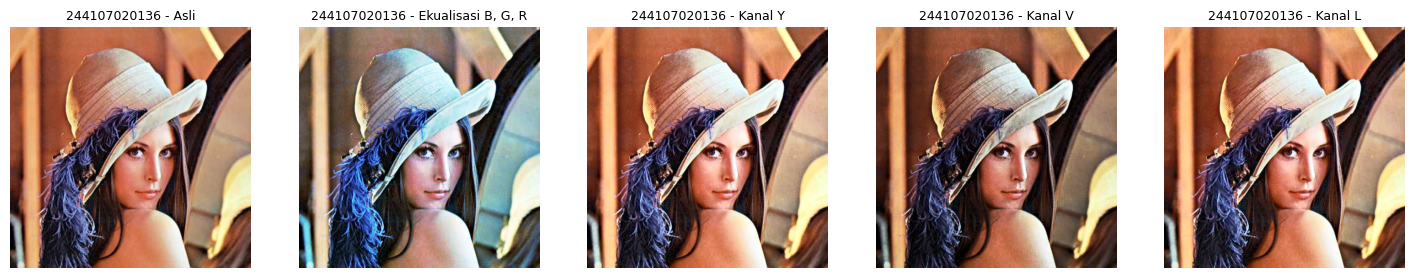

== lena.jpg (tahap 1) ==
Cara                    geser Hue (der)    rerata terang
Asli                               0.00            122.2
Ekualisasi B, G, R                53.03            127.4
Kanal Y                            0.40            127.9
Kanal V                            0.87            100.6
Kanal L                            1.65            122.7


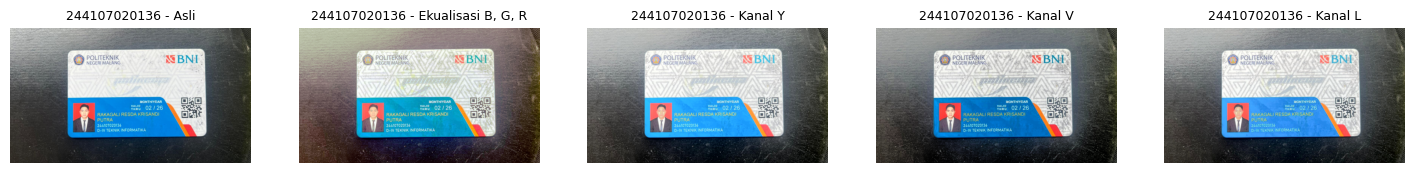

== ktm1d.jpeg (tahap 2) ==
Cara                    geser Hue (der)    rerata terang
Asli                               0.00            114.9
Ekualisasi B, G, R                67.18            126.2
Kanal Y                            0.35            128.2
Kanal V                            2.51            112.5
Kanal L                            7.97            121.4


In [29]:
# tahap 1: citra contoh
_ = ekualisasi_warna(CONTOH + '/lena.jpg', 'lena.jpg (tahap 1)')

# tahap 2: KTM1d.jpg milik Anda
bgr_d, y_d, cr_d, cb_d, citra_d, judul_d = ekualisasi_warna(
    BASE + '/ktm1d.jpeg', 'ktm1d.jpeg (tahap 2)')


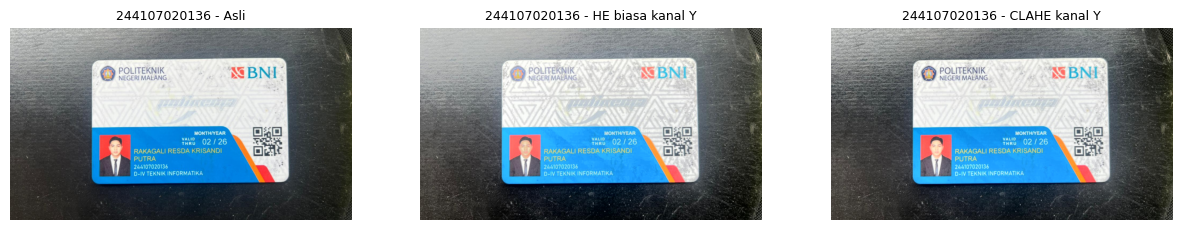

Cara                    geser Hue (der)    rerata terang
Asli                               0.00            114.9
HE biasa kanal Y                   0.35            128.2
CLAHE kanal Y                      0.12            118.8


In [30]:
clahe = cv.createCLAHE(clipLimit=PARAM['clip'],
                       tileGridSize=(PARAM['tile'], PARAM['tile']))
he_y_clahe = cv.cvtColor(cv.merge([clahe.apply(y_d), cr_d, cb_d]),
                         cv.COLOR_YCrCb2BGR)

pilihan = [('Asli', bgr_d), ('HE biasa kanal Y', citra_d[2]),
           ('CLAHE kanal Y', he_y_clahe)]
plt.figure(figsize=(15, 4))
for i, (t, c) in enumerate(pilihan, 1):
    plt.subplot(1, 3, i)
    plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB))
    plt.title(NIM + ' - ' + t, fontsize=9)
    plt.axis('off')
plt.show()

print('%-22s %16s %16s' % ('Cara', 'geser Hue (der)', 'rerata terang'))
for t, c in pilihan:
    print('%-22s %16.2f %16.1f' % (t, geser_hue(bgr_d, c) * 2,
          cv.cvtColor(c, cv.COLOR_BGR2GRAY).mean()))


selisih maks manual vs equalizeHist: 1
Citra              PSNR        MSE      std   entropi
asli                  -          -    23.22     5.606
HE manual          6.60    14235.2    71.55     5.575
equalizeHist       6.61    14198.1    71.75     5.582
cv.PSNR (pemeriksaan): 6.6084976288060915


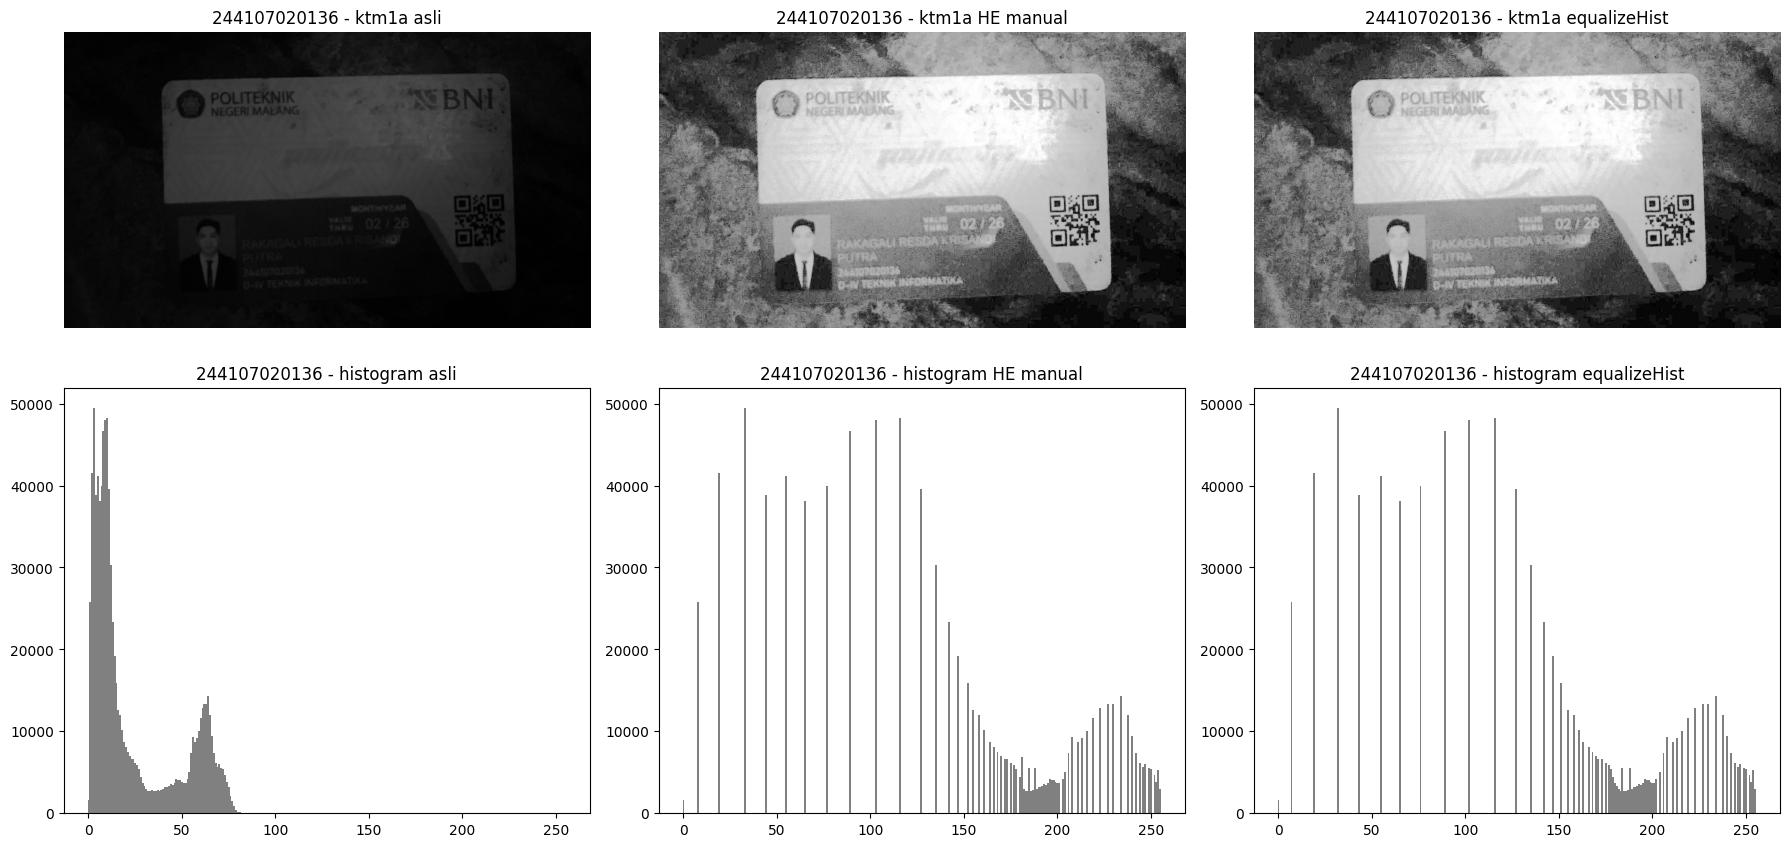

In [32]:
gray = cv.imread(BASE + '/ktm1a.jpeg', cv.IMREAD_GRAYSCALE)
he_man = he_manual(gray)
he_cv  = cv.equalizeHist(gray)
print('selisih maks manual vs equalizeHist:',
      np.abs(he_man.astype(int) - he_cv.astype(int)).max())

def mse(a, b):
    return np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)

def psnr(a, b):
    m = mse(a, b)
    return float('inf') if m == 0 else 10 * np.log10(255.0 ** 2 / m)

def entropi(g):
    p = hist_np(g) / g.size
    p = p[p > 0]
    return -np.sum(p * np.log2(p))

print('%-14s %8s %10s %8s %9s' % ('Citra', 'PSNR', 'MSE', 'std', 'entropi'))
print('%-14s %8s %10s %8.2f %9.3f' % ('asli', '-', '-', gray.std(), entropi(gray)))
for nama, g2 in [('HE manual', he_man), ('equalizeHist', he_cv)]:
    print('%-14s %8.2f %10.1f %8.2f %9.3f'
          % (nama, psnr(gray, g2), mse(gray, g2), g2.std(), entropi(g2)))
print('cv.PSNR (pemeriksaan):', cv.PSNR(gray, he_cv))

fig, axs = plt.subplots(2, 3, figsize=(18, 9))
data = [(gray, 'asli'), (he_man, 'HE manual'), (he_cv, 'equalizeHist')]
for j, (g, t) in enumerate(data):
    axs[0, j].imshow(g, cmap='gray', vmin=0, vmax=255)
    axs[0, j].set_title(NIM + ' - ktm1a ' + t)
    axs[0, j].axis('off')
    axs[1, j].bar(np.arange(256), hist_np(g), width=1.0, color='gray')
    axs[1, j].set_title(NIM + ' - histogram ' + t)
plt.tight_layout()
plt.show()


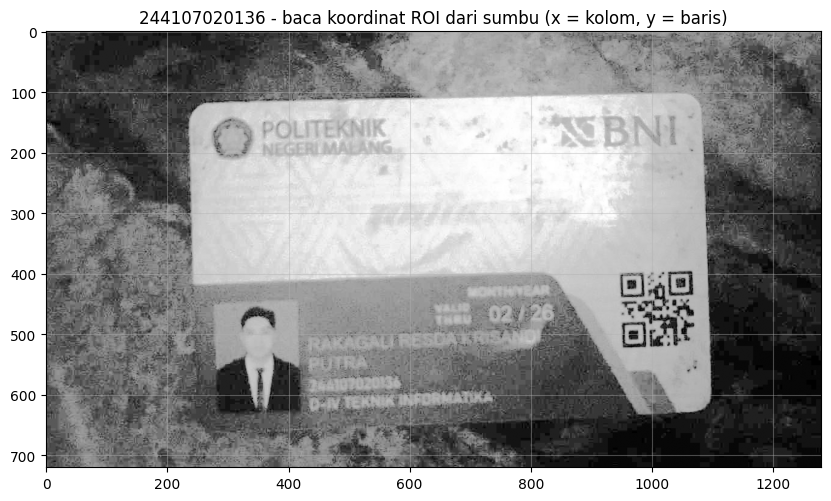

In [33]:
plt.figure(figsize=(10, 7))
plt.imshow(cv.equalizeHist(gray), cmap='gray')
plt.title(NIM + ' - baca koordinat ROI dari sumbu (x = kolom, y = baris)')
plt.grid(True, alpha=0.4)
plt.show()


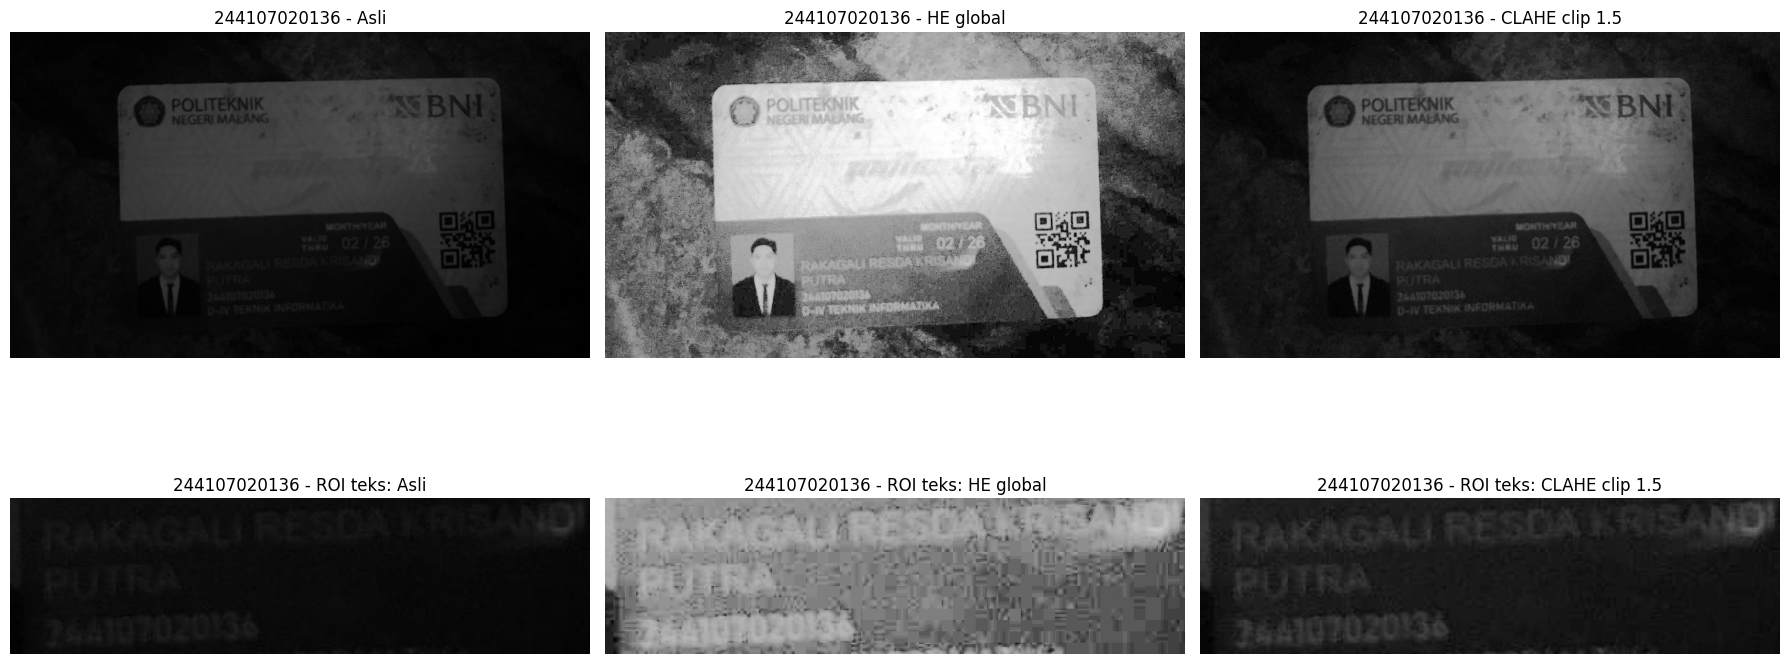

Citra              std ROI teks
Asli                       5.39
HE global                 30.78
CLAHE clip 1.5            11.47


In [35]:
def clahe_gray(g, clip, tile):
    return cv.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(g)

roi_teks = (490, 600, 410, 820)
y1, y2, x1, x2 = roi_teks
clahe_1 = clahe_gray(gray, PARAM['clip'], PARAM['tile'])
hasil = [('Asli', gray), ('HE global', he_cv),
         ('CLAHE clip ' + str(PARAM['clip']), clahe_1)]

fig, axs = plt.subplots(2, 3, figsize=(18, 9))
for j, (t, g) in enumerate(hasil):
    axs[0, j].imshow(g, cmap='gray', vmin=0, vmax=255)
    axs[0, j].set_title(NIM + ' - ' + t)
    axs[0, j].axis('off')
    axs[1, j].imshow(g[y1:y2, x1:x2], cmap='gray', vmin=0, vmax=255)
    axs[1, j].set_title(NIM + ' - ROI teks: ' + t)
    axs[1, j].axis('off')
plt.tight_layout()
plt.show()

print('%-18s %12s' % ('Citra', 'std ROI teks'))
for t, g in hasil:
    print('%-18s %12.2f' % (t, g[y1:y2, x1:x2].std()))


clipLimit    std ROI teks   std area datar
1.0                  9.37             2.01
1.5                 11.47             2.50
2.0                 13.48             2.76
3.0                 16.86             3.68


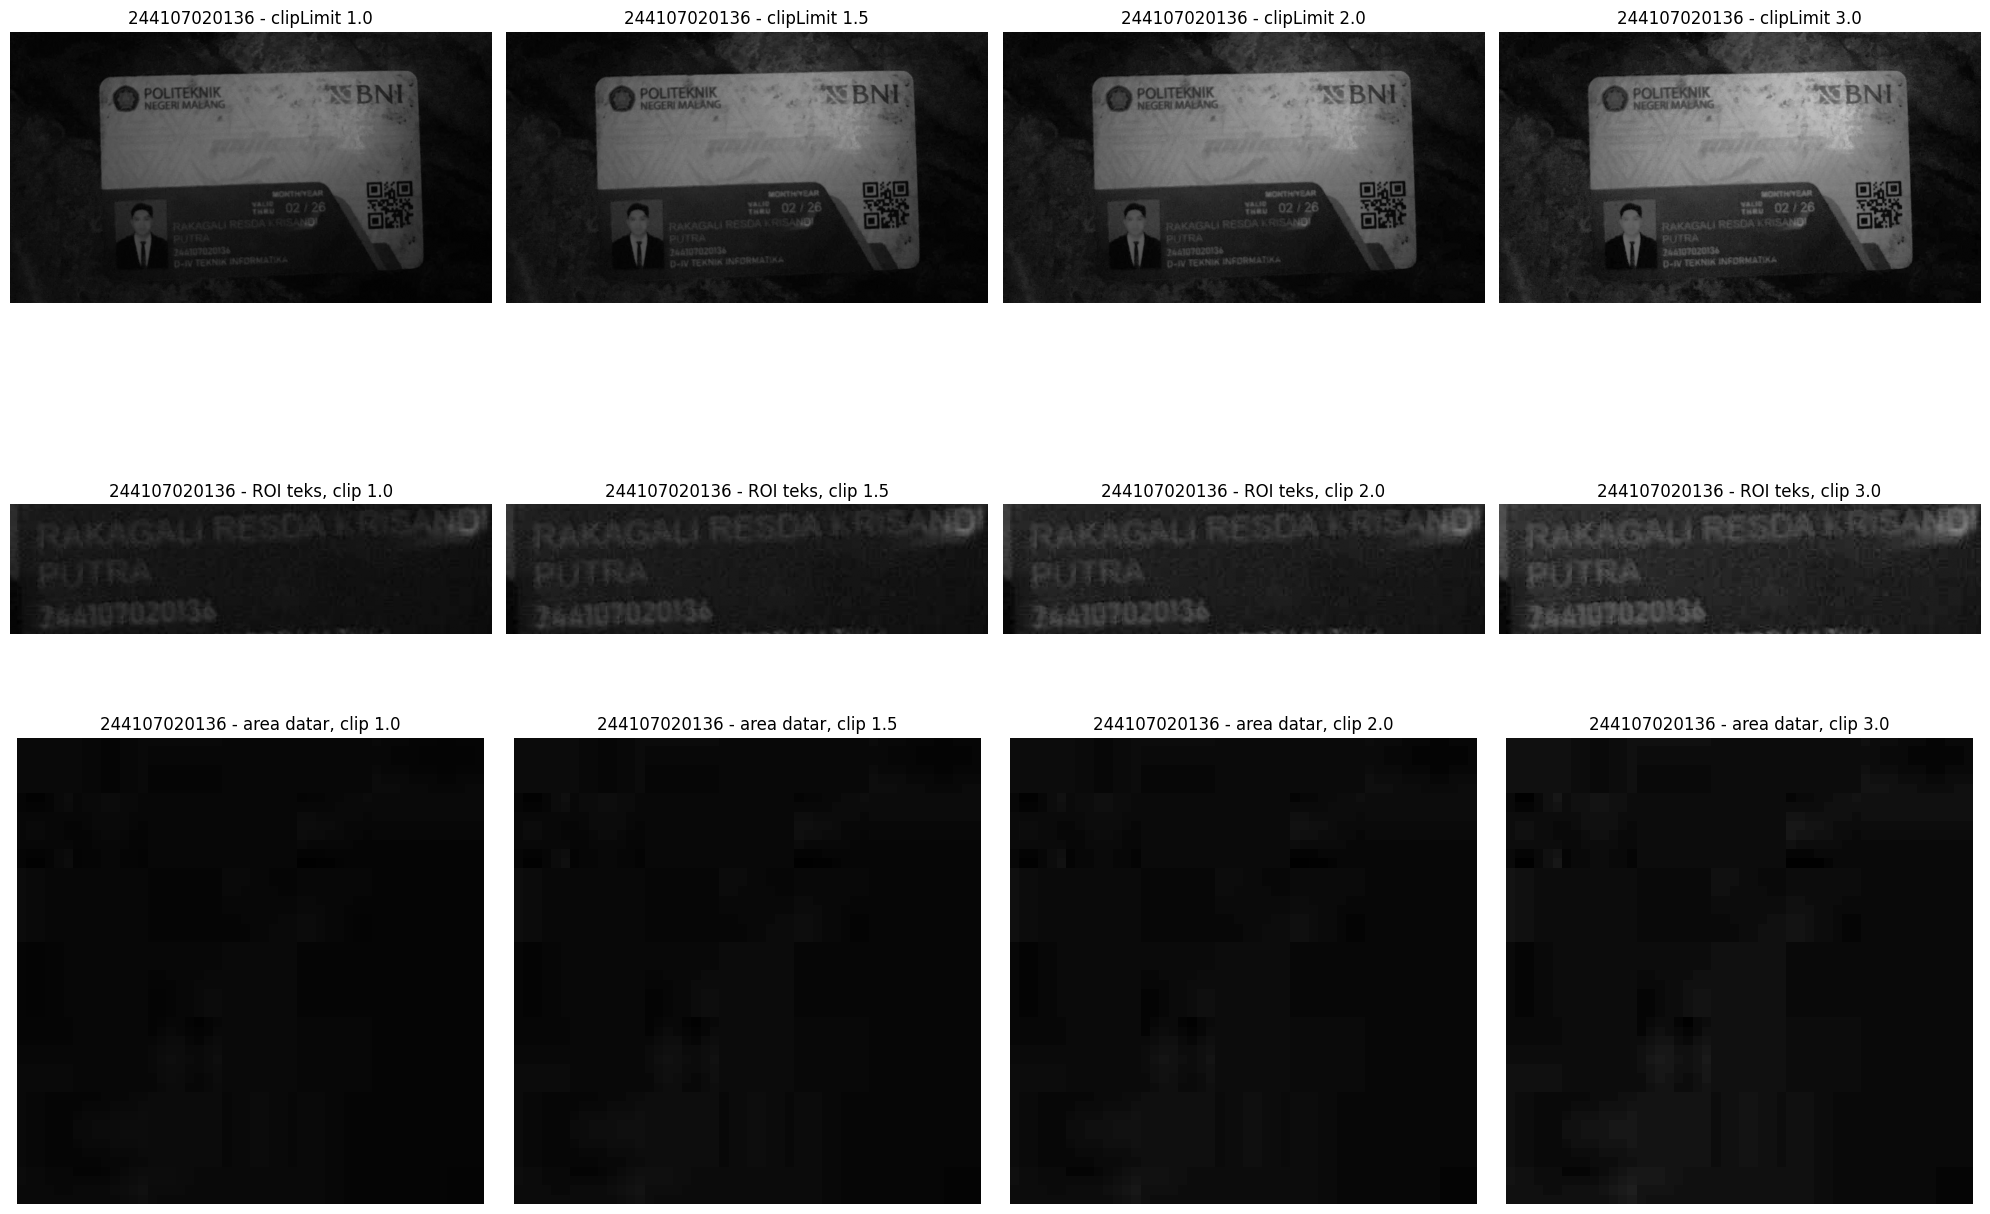

In [36]:
clip_uji  = [1.0, PARAM['clip'], 2.0, 3.0]
roi_datar = (10, 60, 10, 60)
q1, q2, p1, p2 = roi_datar

fig, axs = plt.subplots(3, 4, figsize=(20, 13))
print('%-10s %14s %16s' % ('clipLimit', 'std ROI teks', 'std area datar'))
for j, cl in enumerate(clip_uji):
    g = clahe_gray(gray, cl, PARAM['tile'])
    axs[0, j].imshow(g, cmap='gray', vmin=0, vmax=255)
    axs[0, j].set_title(NIM + ' - clipLimit ' + str(cl))
    axs[1, j].imshow(g[y1:y2, x1:x2], cmap='gray', vmin=0, vmax=255)
    axs[1, j].set_title(NIM + ' - ROI teks, clip ' + str(cl))
    axs[2, j].imshow(g[q1:q2, p1:p2], cmap='gray', vmin=0, vmax=255)
    axs[2, j].set_title(NIM + ' - area datar, clip ' + str(cl))
    for i in range(3):
        axs[i, j].axis('off')
    print('%-10s %14.2f %16.2f' % (cl, g[y1:y2, x1:x2].std(), g[q1:q2, p1:p2].std()))
plt.tight_layout()
plt.show()


In [37]:
def floyd_steinberg(gray, L=2):
    img = gray.astype(np.float32).copy()
    step = 255.0 / (L - 1)
    H, W = img.shape
    for y in range(H):
        for x in range(W):
            lama = img[y, x]
            baru = np.round(lama / step) * step     # warna palet terdekat
            img[y, x] = baru
            error = lama - baru
            if x + 1 < W:               img[y,   x+1] += error * 7 / 16
            if x > 0 and y + 1 < H:     img[y+1, x-1] += error * 3 / 16
            if y + 1 < H:               img[y+1, x  ] += error * 5 / 16
            if x + 1 < W and y + 1 < H: img[y+1, x+1] += error * 1 / 16
    return np.clip(img, 0, 255).astype(np.uint8)

def tampil_dither(path, L, judul):
    gray = cv.imread(path, cv.IMREAD_GRAYSCALE)
    assert gray is not None, 'Berkas tidak terbaca: ' + path
    t0 = time.perf_counter()
    hasil = floyd_steinberg(gray, L)
    print(judul, '| L =', L, '| level hasil:', np.unique(hasil),
          '| %.1f s' % (time.perf_counter() - t0))
    print('rerata asli %.2f | rerata hasil %.2f' % (gray.mean(), hasil.mean()))
    fig, axs = plt.subplots(1, 2, figsize=(14, 7))
    axs[0].imshow(gray, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    axs[0].set_title(NIM + ' - ' + judul + ' asli')
    axs[1].imshow(hasil, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    axs[1].set_title(NIM + ' - Floyd-Steinberg, L = ' + str(L))
    for a in axs:
        a.axis('off')
    plt.show()
    return gray, hasil


lena.jpg (tahap 1) | L = 2 | level hasil: [  0 255] | 3.5 s
rerata asli 122.24 | rerata hasil 122.22


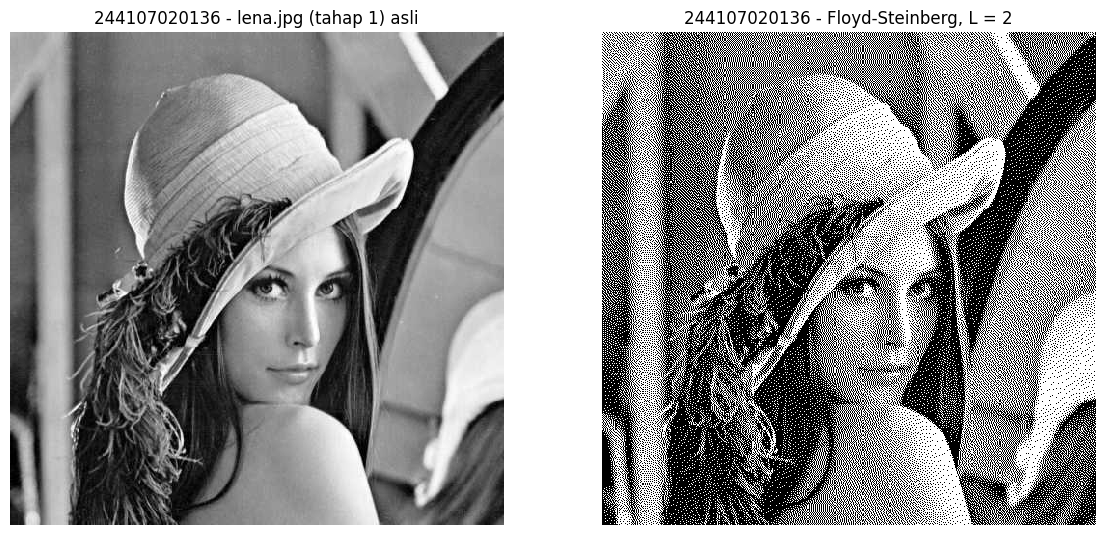

In [38]:
g_lena, d_lena = tampil_dither(CONTOH + '/lena.jpg', 2, 'lena.jpg (tahap 1)')

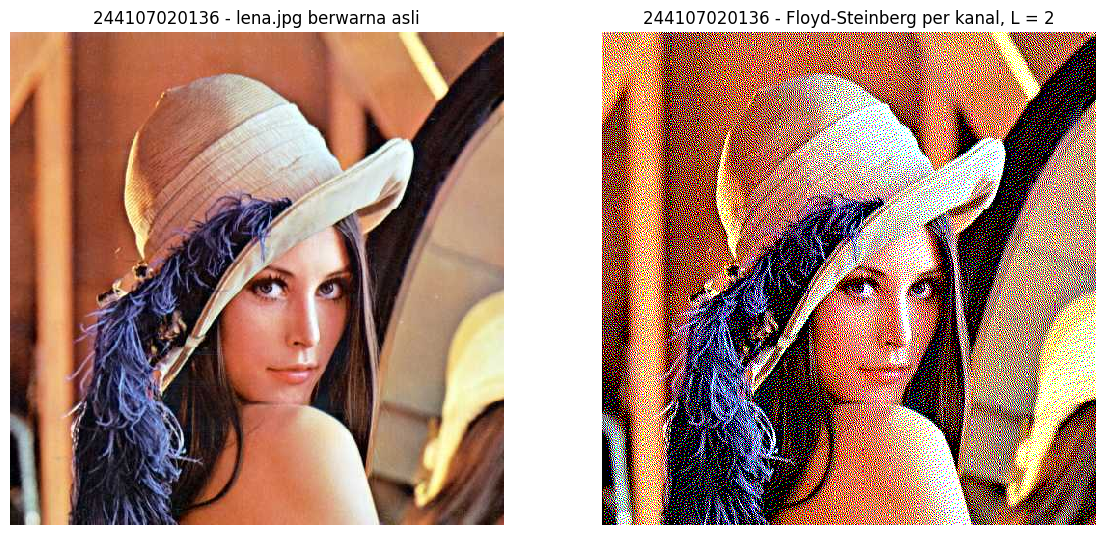

In [39]:
def floyd_warna(bgr, L):
    return cv.merge([floyd_steinberg(c, L) for c in cv.split(bgr)])

lena_bgr = cv.imread(CONTOH + '/lena.jpg')
lena_dw  = floyd_warna(lena_bgr, 2)          # 2 level per kanal = 8 warna
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
axs[0].imshow(cv.cvtColor(lena_bgr, cv.COLOR_BGR2RGB), interpolation='nearest')
axs[0].set_title(NIM + ' - lena.jpg berwarna asli')
axs[1].imshow(cv.cvtColor(lena_dw, cv.COLOR_BGR2RGB), interpolation='nearest')
axs[1].set_title(NIM + ' - Floyd-Steinberg per kanal, L = 2')
for a in axs:
    a.axis('off')
plt.show()


ktm1b.jpeg (tahap 2) | L = 4 | level hasil: [  0  85 170 255] | 10.2 s
rerata asli 174.97 | rerata hasil 174.97


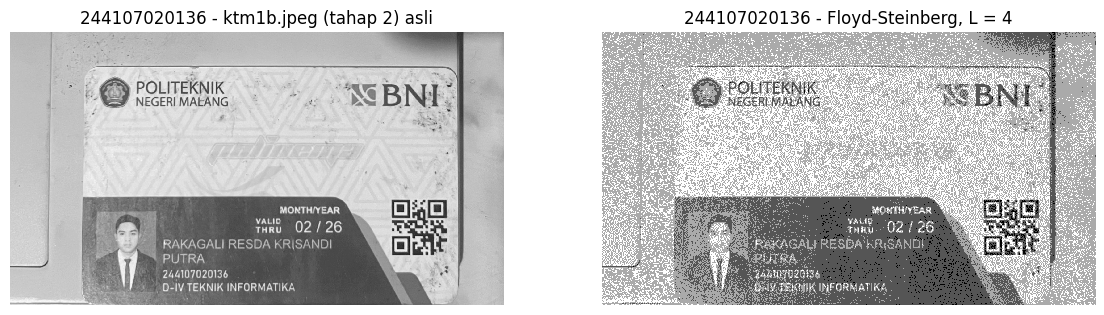

In [40]:
g_ktm, d_ktm = tampil_dither(BASE + '/ktm1b.jpeg', PARAM['L'], 'ktm1b.jpeg (tahap 2)')

In [42]:
gray = cv.imread(BASE + '/ktm1b.jpeg', cv.IMREAD_GRAYSCALE)
L    = PARAM['L']
step = 255.0 / (L - 1)
blok = gray[0:2, 0:3].astype(np.float32)     # 2 baris x 3 kolom pojok kiri atas
print('palet :', [round(k * step) for k in range(L)], '| step =', step)
print('blok asli (baris 0-1, kolom 0-2):')
print(blok)

# satu langkah = piksel pertama yang diproses, (y=0, x=0)
y, x  = 0, 0
lama  = blok[y, x]
baru  = np.round(lama / step) * step
error = lama - baru
print('lama = %.4f | lama/step = %.4f | baru = %.1f | error = %.4f'
      % (lama, lama / step, baru, error))

akhir = blok.copy()
akhir[y, x] = baru
akhir[y, x + 1]     += error * 7 / 16        # kanan
akhir[y + 1, x]     += error * 5 / 16        # bawah
akhir[y + 1, x + 1] += error * 1 / 16        # kanan-bawah
# tetangga kiri-bawah (3/16) di luar batas karena x = 0 -> dilewati
print('tambahan: kanan %.4f | bawah %.4f | kanan-bawah %.4f | kiri-bawah dilewati'
      % (error * 7 / 16, error * 5 / 16, error * 1 / 16))
print('blok setelah satu langkah:')
print(akhir)

# verifikasi dengan fungsi lengkap: piksel (0,0) harus sama dengan baru
assert int(floyd_steinberg(gray[0:2, 0:3], L)[0, 0]) == int(round(float(baru)))
print('verifikasi piksel (0,0) dengan floyd_steinberg(): LOLOS')


palet : [0, 85, 170, 255] | step = 85.0
blok asli (baris 0-1, kolom 0-2):
[[188. 187. 187.]
 [184. 184. 184.]]
lama = 188.0000 | lama/step = 2.2118 | baru = 170.0 | error = 18.0000
tambahan: kanan 7.8750 | bawah 5.6250 | kanan-bawah 1.1250 | kiri-bawah dilewati
blok setelah satu langkah:
[[170.    194.875 187.   ]
 [189.625 185.125 184.   ]]
verifikasi piksel (0,0) dengan floyd_steinberg(): LOLOS


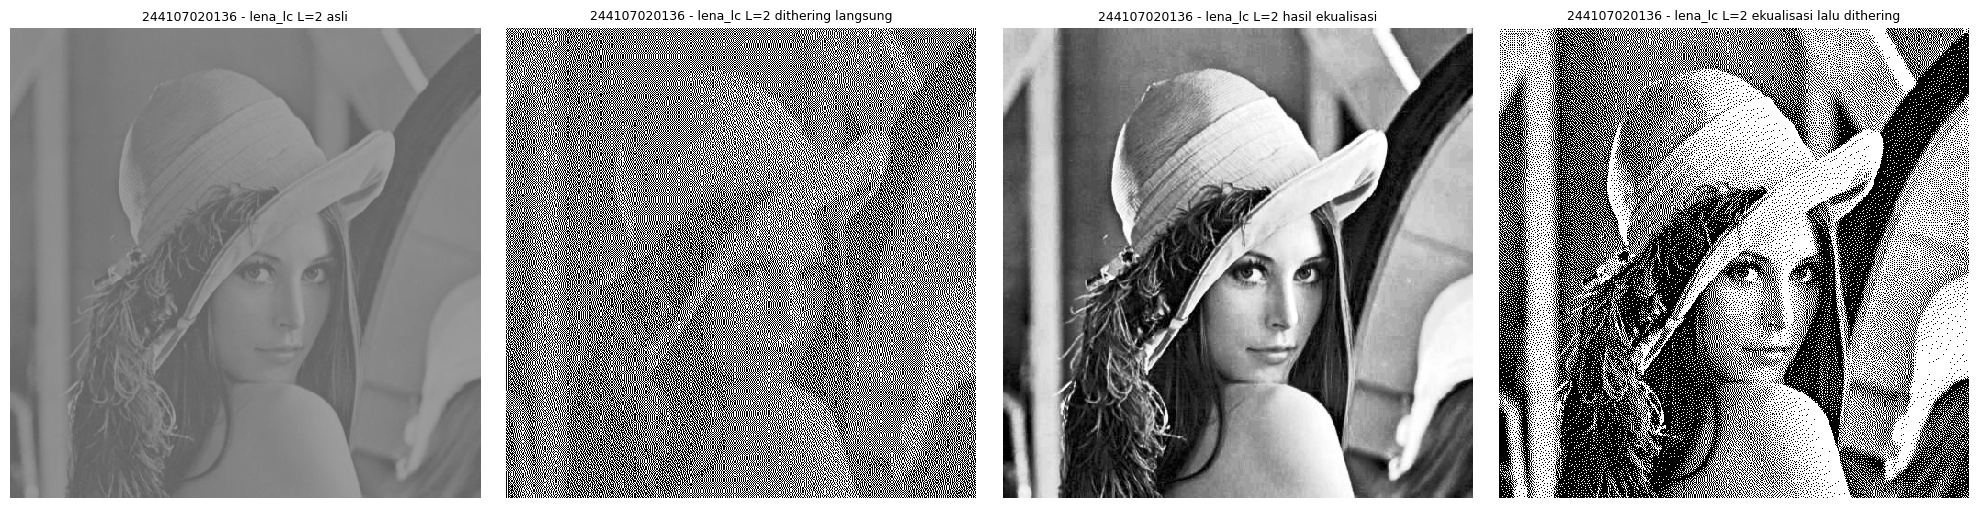

level hasil A: [  0 255] | B: [  0 255]
Citra                          rerata      std
asli                           126.27    14.94
dithering langsung             126.26   127.49
hasil ekualisasi               130.10    73.59
ekualisasi lalu dithering      130.10   127.47


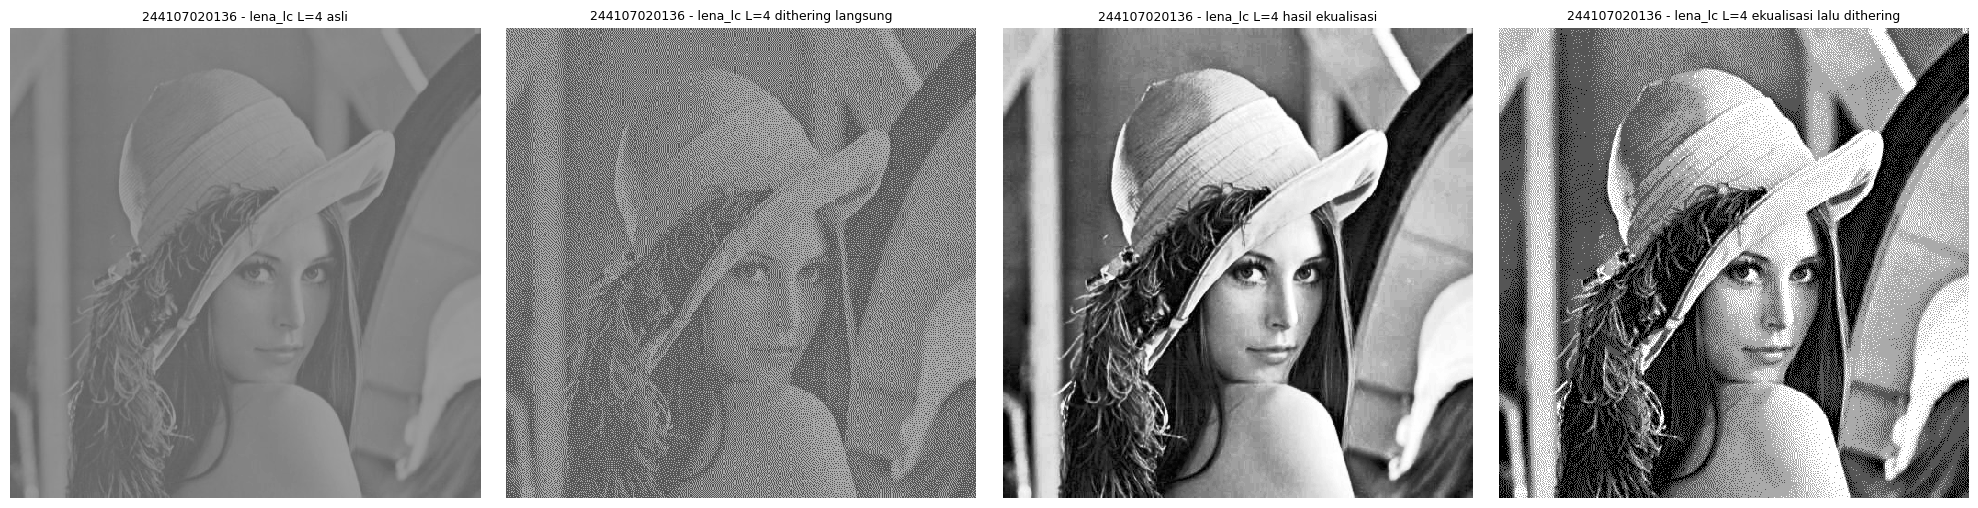

level hasil A: [ 85 170] | B: [  0  85 170 255]
Citra                          rerata      std
asli                           126.27    14.94
dithering langsung             126.26    42.48
hasil ekualisasi               130.10    73.59
ekualisasi lalu dithering      130.10    80.86


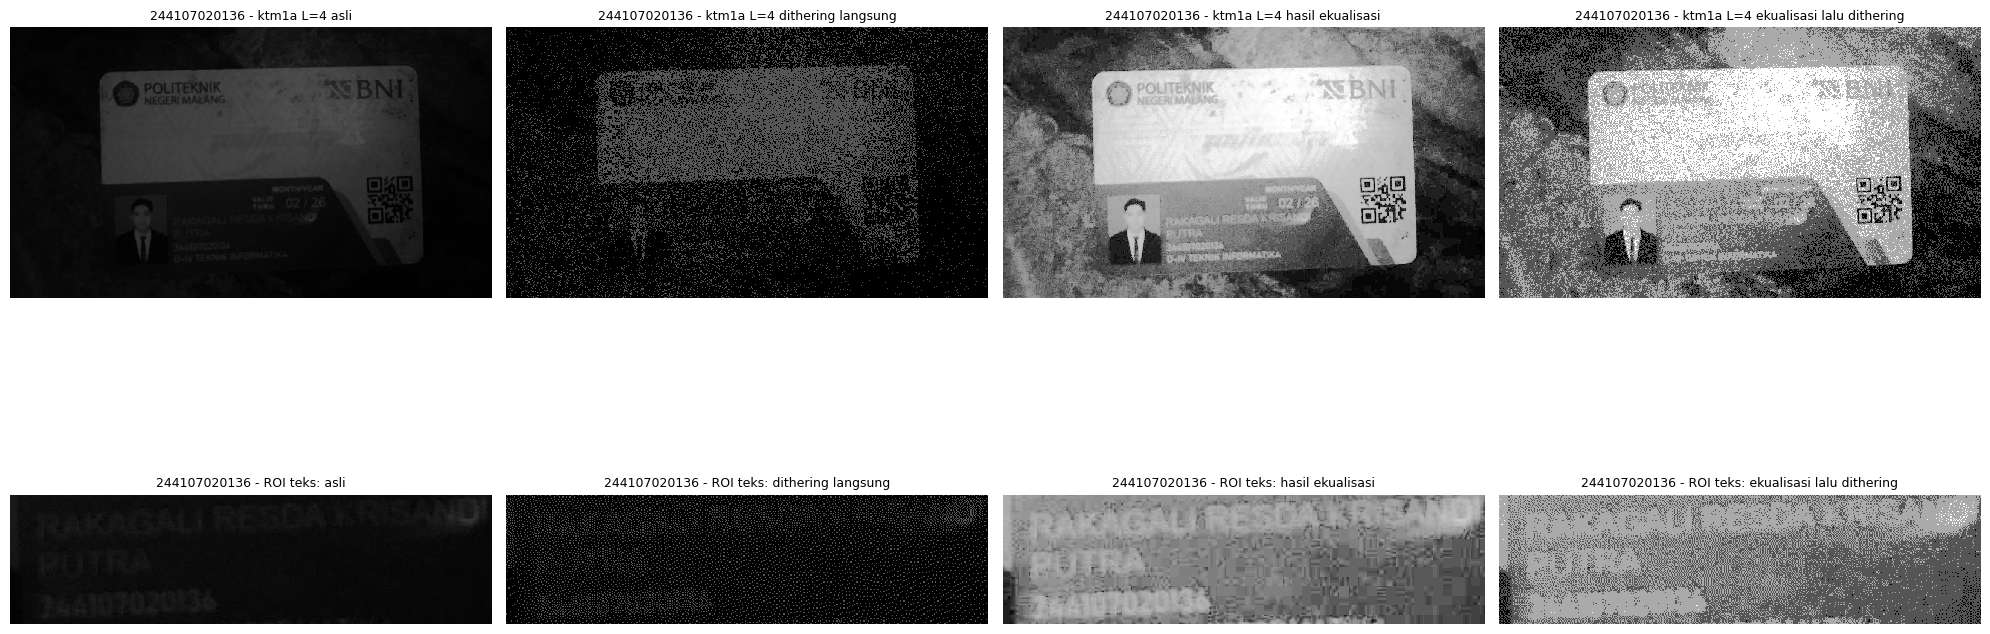

level hasil A: [ 0 85] | B: [  0  85 170 255]
Citra                          rerata      std
asli                            23.52    23.22
dithering langsung              23.49    38.01
hasil ekualisasi               130.91    71.75
ekualisasi lalu dithering      130.90    79.39
std ROI teks: A = 30.75 | B = 44.63


In [44]:
def dither_ekualisasi(path, L, judul, roi=None):
    gray = cv.imread(path, cv.IMREAD_GRAYSCALE)
    assert gray is not None, 'Berkas tidak terbaca: ' + path
    he = cv.equalizeHist(gray)
    langsung = floyd_steinberg(gray, L)     # urutan A: dithering langsung
    urut_b   = floyd_steinberg(he, L)       # urutan B: ekualisasi lalu dithering
    data = [(gray, 'asli'), (langsung, 'dithering langsung'),
            (he, 'hasil ekualisasi'), (urut_b, 'ekualisasi lalu dithering')]
    baris = 2 if roi else 1
    fig, axs = plt.subplots(baris, 4, figsize=(20, 5 * baris), squeeze=False)
    for j, (g, t) in enumerate(data):
        axs[0, j].imshow(g, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        axs[0, j].set_title(NIM + ' - ' + judul + ' ' + t, fontsize=9)
        axs[0, j].axis('off')
        if roi:
            a1, a2, b1, b2 = roi
            axs[1, j].imshow(g[a1:a2, b1:b2], cmap='gray', vmin=0, vmax=255,
                             interpolation='nearest')
            axs[1, j].set_title(NIM + ' - ROI teks: ' + t, fontsize=9)
            axs[1, j].axis('off')
    plt.tight_layout()
    plt.show()
    print('level hasil A:', np.unique(langsung), '| B:', np.unique(urut_b))
    print('%-28s %8s %8s' % ('Citra', 'rerata', 'std'))
    for g, t in data:
        print('%-28s %8.2f %8.2f' % (t, g.mean(), g.std()))
    if roi:
        a1, a2, b1, b2 = roi
        print('std ROI teks: A = %.2f | B = %.2f'
              % (langsung[a1:a2, b1:b2].std(), urut_b[a1:a2, b1:b2].std()))

# tahap 1: modul tidak menyebut L untuk contoh ini, coba L = 2 dan L = 4
dither_ekualisasi(CONTOH + '/lena_lc.jpg', 2, 'lena_lc L=2')
dither_ekualisasi(CONTOH + '/lena_lc.jpg', 4, 'lena_lc L=4')

# tahap 2: KTM1a.jpg dengan L milik Anda, roi_teks dari Langkah 19
dither_ekualisasi(BASE + '/ktm1a.jpeg', PARAM['L'], 'ktm1a L=' + str(PARAM['L']), roi_teks)
